### Predicting Student Mental Health Score from Social Media Usage

###### Problem: I am going to predict a student's Mental_Health_Score (a continuous score from ~3 to ~10) using their social media habits, study time, sleep, physical activity, and stress level. This is a regression problem since the target is a number, not a category.
###### Dataset: Student_Social_Media_And_Mental_Health_Impact.csv — 5,000 students, 13 columns covering demographics (Age, Gender, Country), platform usage (Avg_Daily_Usage_Hours, Daily_Unlocks, Most_Used_Platform), lifestyle (Study_Hours, Sleep_Hours_Per_Night, Physical_Activity_Hours), and Stress_Level.

In [127]:
# Importing basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [128]:
# loading dataset
data = pd.read_csv("Student Social Media And Mental Health Impact.csv")

In [129]:
data.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [130]:
data.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [131]:
data.shape

(5000, 13)

In [132]:
data.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [133]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [134]:
data.describe()
# we got negative value in the min physical activity hours time cannot be negative

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [135]:
data.duplicated().sum()

np.int64(2)

#### EDA

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

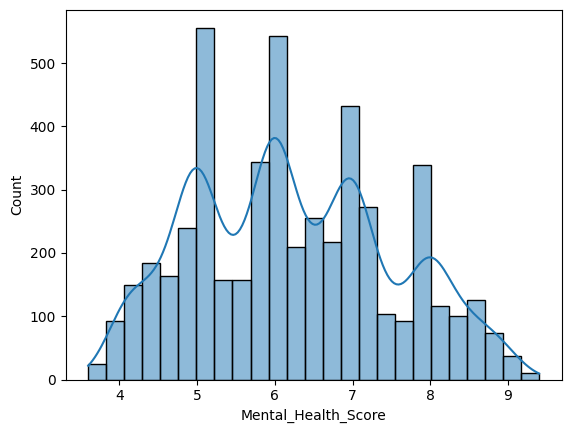

In [136]:
sns.histplot(data['Mental_Health_Score'], kde=True)

<Axes: xlabel='Physical_Activity_Hours', ylabel='Count'>

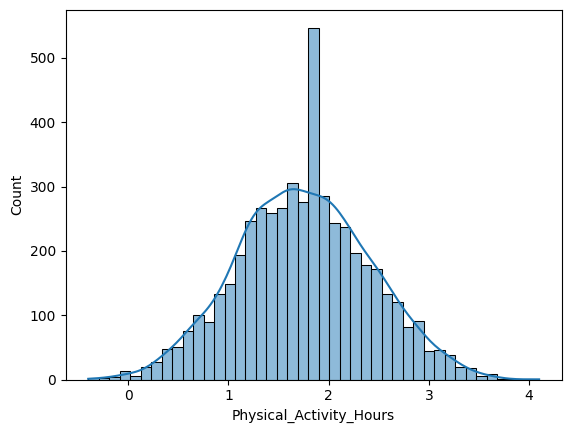

In [137]:
sns.histplot(data['Physical_Activity_Hours'], kde=True)

<Axes: >

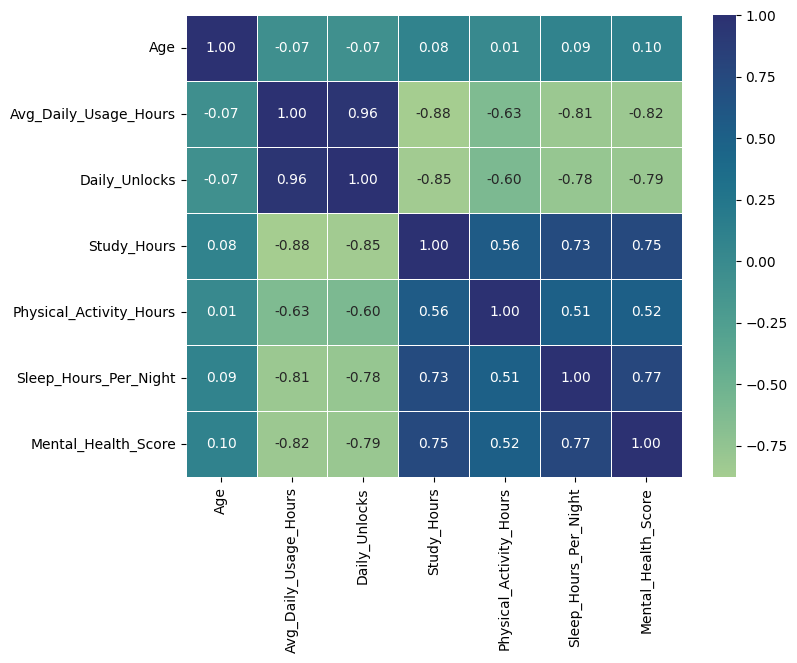

In [138]:
corr = data.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=corr,
    annot=True,  
    fmt=".2f",  
    cmap="crest", 
    linewidths=0.5,  
    linecolor="white", 
    cbar=True, 
)


In [139]:
# Lets see the relation of stree with the mental health score through boxmap also show us the outliers 
data['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

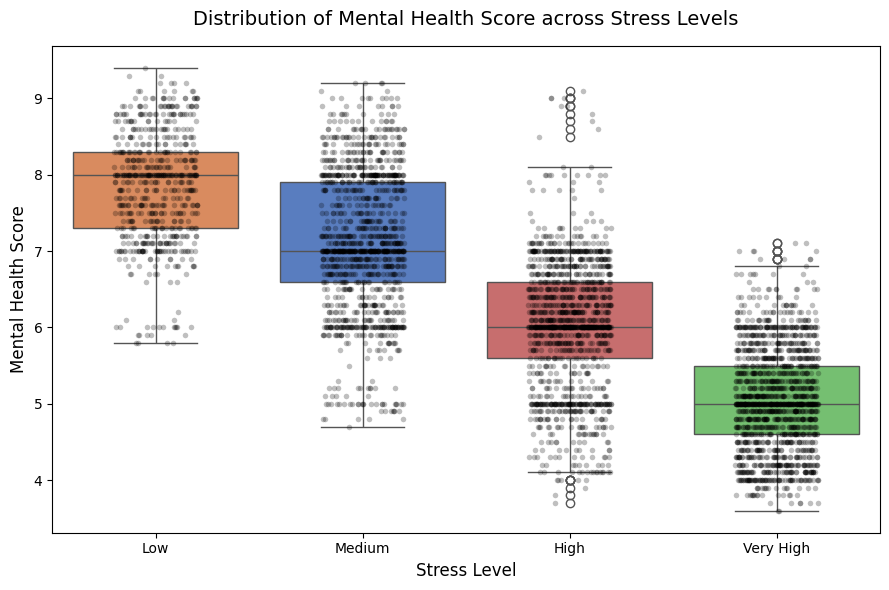

In [140]:
order = ['Low', 'Medium', 'High', 'Very High']
plt.figure(figsize=(9, 6))


sns.boxplot(
    data=data,
    x="Stress_Level",
    y="Mental_Health_Score",
    palette="muted",
    hue="Stress_Level",
    legend=False,
    order=order
)

sns.stripplot(
    data=data,
    x="Stress_Level",
    y="Mental_Health_Score",
    color="black",
    alpha=0.25,
    size=4,
    jitter=0.2,
)

plt.title(
    "Distribution of Mental Health Score across Stress Levels",
    fontsize=14,
    pad=15,
)
plt.xlabel("Stress Level", fontsize=12)
plt.ylabel("Mental Health Score", fontsize=12)

plt.tight_layout()
plt.show()


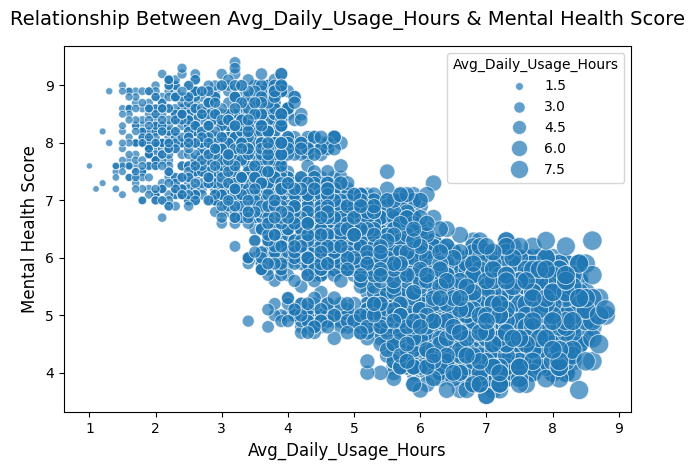

In [141]:
sns.scatterplot(
    data=data,
    x="Avg_Daily_Usage_Hours",
    y="Mental_Health_Score",
    palette="flare",  
    size="Avg_Daily_Usage_Hours",  
    sizes=(20, 200),  
    alpha=0.7,  
)

# Customize titles and clear labels
plt.title(
    "Relationship Between Avg_Daily_Usage_Hours & Mental Health Score",
    fontsize=14,
    pad=15,
)
plt.xlabel("Avg_Daily_Usage_Hours", fontsize=12)
plt.ylabel("Mental Health Score", fontsize=12)
plt.tight_layout()
plt.show()

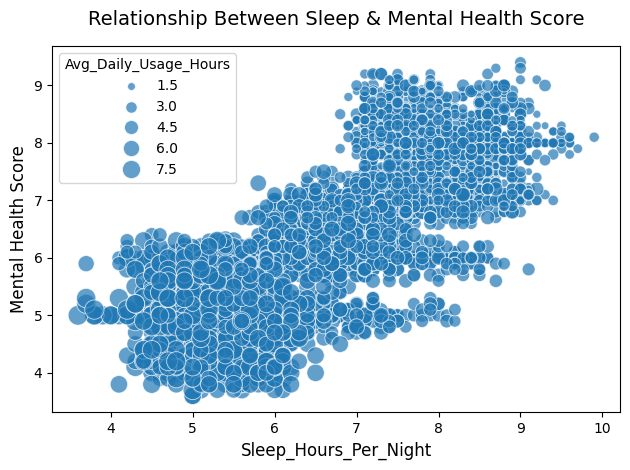

In [142]:
sns.scatterplot(
    data=data,
    x="Sleep_Hours_Per_Night",
    y="Mental_Health_Score",
    palette="flare",  
    size="Avg_Daily_Usage_Hours",  
    sizes=(20, 200),  
    alpha=0.7
)

# Customize titles and clear labels
plt.title(
    "Relationship Between Sleep & Mental Health Score",
    fontsize=14,
    pad=15,
)
plt.xlabel("Sleep_Hours_Per_Night", fontsize=12)
plt.ylabel("Mental Health Score", fontsize=12)
plt.tight_layout()
plt.show()

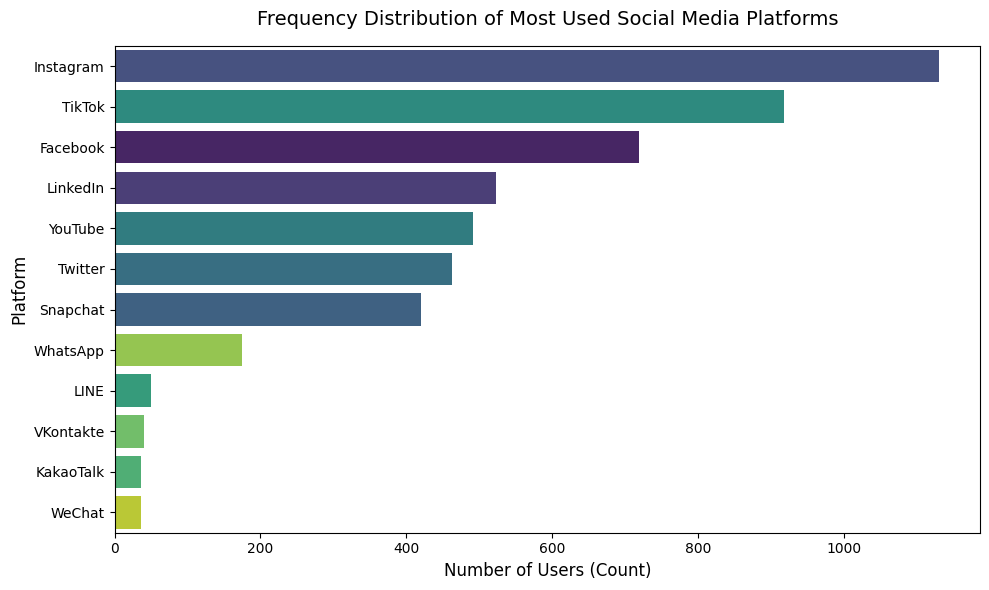

In [143]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    y="Most_Used_Platform",
    order=data["Most_Used_Platform"].value_counts().index, 
    palette="viridis",  
    hue="Most_Used_Platform", 
    legend=False,
)

plt.title(
    "Frequency Distribution of Most Used Social Media Platforms",
    fontsize=14,
    pad=15,
)
plt.xlabel("Number of Users (Count)", fontsize=12)
plt.ylabel("Platform", fontsize=12)
plt.tight_layout()
plt.show()

#### Data Cleaning

In [144]:
numerical = data.select_dtypes(include='number')
numerical.head()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
0,21,4.0,134,4.5,2.2,6.7,6.8
1,23,1.6,73,7.0,2.4,8.6,7.6
2,22,4.6,166,4.0,1.8,6.7,7.0
3,18,7.0,220,1.0,1.7,5.4,5.3
4,24,7.5,237,1.0,1.1,5.0,4.4


In [145]:
Q1 = numerical.quantile(0.25)
Q3 = numerical.quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

In [146]:
outliers = (numerical < lower_bound) | (numerical > upper_bound)
outliers.sum()

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64

In [147]:
# Dropping the duplicate values 
data = data.drop_duplicates()

In [148]:
# Dropping the negative value in the column 'Physical_Activity_Hours'
data = data[data['Physical_Activity_Hours'] >= 0]
data = data.drop_duplicates()

In [149]:
data.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000
mean,20.822374,5.074539,171.347835,3.010706,1.754671,6.636949,6.233841
std,1.737116,1.652778,42.827688,1.637380,0.663322,1.221215,1.278005
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [150]:
numerical.skew()

Age                        0.155325
Avg_Daily_Usage_Hours      0.005606
Daily_Unlocks              0.002351
Study_Hours                0.435819
Physical_Activity_Hours    0.039971
Sleep_Hours_Per_Night      0.124050
Mental_Health_Score        0.206567
dtype: float64

In [151]:
data.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [152]:
data['Country'].value_counts()

Country
Other        1871
India         388
USA           353
Canada        230
Australia     198
             ... 
Armenia         1
Bosnia          1
Kuwait          1
Yemen           1
Syria           1
Name: count, Length: 111, dtype: int64

In [153]:
top_countries = data['Country'].value_counts().index[:10].to_list()

In [154]:
def grouping(country):
    if country in top_countries:
        return country
    else:
        return 'Other'

In [155]:
data['Grouped_Country'] = data['Country'].apply(grouping)

In [156]:
data['Grouped_Country'].value_counts()

Grouped_Country
Other        3223
India         388
USA           353
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

In [157]:
numerical = data.select_dtypes(include='number')
numerical.skew()

Age                        0.153729
Avg_Daily_Usage_Hours      0.006916
Daily_Unlocks              0.004558
Study_Hours                0.433823
Physical_Activity_Hours    0.075382
Sleep_Hours_Per_Night      0.121965
Mental_Health_Score        0.205218
dtype: float64

In [158]:
data.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Grouped_Country
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other


In [159]:
from sklearn.model_selection import train_test_split
# Seperating each columns to perform specific operation on the specific type of columns

skwewd_col         = ['Study_Hours'] # to remove skewness by log transformation
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level'] # to preserve the order of values 
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Grouped_Country"]


main_cols = skwewd_col + other_numeric_cols + ordinal_col + normal_col
X = data[main_cols]
y = data['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [160]:
X_train.head()

,Study_Hours,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Gender,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Grouped_Country
1407,1.7,22,6.4,195,0.6,5.8,Very High,Male,Undergraduate,WhatsApp,Education,Mexico
3912,4.0,19,4.7,169,1.7,7.1,High,Female,Undergraduate,LinkedIn,Education,Other
801,1.0,23,6.4,213,0.9,5.4,Very High,Male,Graduate,TikTok,Entertainment,Other
1288,5.4,19,3.0,112,2.5,8.6,Medium,Female,Undergraduate,LINE,News,Other
2172,2.4,21,4.7,158,2.0,7.3,High,Male,Undergraduate,Instagram,Entertainment,Other


#### Creating Pipelines

In [161]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder

# Skewed features
skew = Pipeline(steps=[
    ('log transformation', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])

# Numerical features
num = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Order-based features
order = Pipeline(steps=[
    ('order', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

# Normal features
normal = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

# Create column transformer
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(transformers=[
    ("Skewed Pipeline", skew, skwewd_col),
    ("Numerical Pipeline", num, other_numeric_cols),
    ("Ordinal Pipline", order, ordinal_col),
    ("Normal Pipeline", normal, normal_col)
])

In [163]:
# Model pipeline for linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

linear = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', LinearRegression())
])

linear.fit(X_train, y_train)
lr_prediction = linear.predict(X_test)
lr_pred_train = linear.predict(X_train)

lr_r2_test  = r2_score(y_test, lr_prediction)
lr_r2_train = r2_score(y_train, lr_pred_train)
lr_mae         = mean_absolute_error(y_test, lr_prediction)

print(f"Accuracy of Training {lr_r2_train}")
print(f"Accuracy of Testing {lr_r2_test}")
print(f'MAE {lr_mae}')

Accuracy of Training 0.7233143016461888
Accuracy of Testing 0.7407562540314494
MAE 0.5209052730542254


In [ ]:
# Model pipeline for Random Forest
from sklearn.ensemble import RandomForestRegressor

rf = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('rf_model', RandomForestRegressor(random_state=42))
])

rf.fit(X_train, y_train)
rf_prediction = rf.predict(X_test)
rf_pred_train = rf.predict(X_train)

rf_r2_test  = r2_score(y_test, rf_prediction)
rf_r2_train = r2_score(y_train, rf_pred_train)
rf_mae         = mean_absolute_error(y_test, rf_prediction)

print(f"Accuracy of Training {rf_r2_train}")
print(f"Accuracy of Testing {rf_r2_test}")
print(f'MAE {rf_mae}')

Accuracy of Training 0.9805954570958927
Accuracy of Testing 0.8862990417227845
MAE 0.3285992317969273


#### Hyperprameter tuning

In [172]:
from sklearn.model_selection import RandomizedSearchCV

random_grid = {'rf_model__max_depth': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, None],
               'rf_model__min_samples_leaf': [1, 2, 4],
               'rf_model__min_samples_split': [2, 5, 10],
               'rf_model__n_estimators': [130, 180, 230]}

random_search = RandomizedSearchCV(estimator=rf, param_distributions=random_grid, n_iter=15, cv=5, verbose=2, random_state=42, n_jobs=-1, scoring='r2')

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [10, 20, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [130, 180, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to

In [174]:
random_search.best_params_

{'model__n_estimators': 230,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_depth': 60}

In [175]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")

R2 Score for random forest after hyperparameter tuning 0.8875764695794153
MAE Score for random forest after hyperparameter tuning 0.3269700487932389


#### Exporting the model

In [177]:
import joblib

joblib.dump(rf, 'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']